# PROJECT 3: SME REVENUE PREDICTION USING REGRESSION AND MACHINE LEARNING

## 1. Project Overview

This project applies regression analysis and machine learning techniques to predict SME revenue using business and operational characteristics.

The analysis compares Multiple Linear Regression and Random Forest Regression to assess their predictive performance on a synthetic SME dataset.

## 2. Project Objectives

- Generate and inspect a structured SME dataset.
- Explore relationships between business characteristics and revenue.
- Prepare features for predictive modelling.
- Develop and compare regression models.
- Evaluate model performance using MAE, RMSE and R².
- Interpret model results and identify limitations.

## 3. Research Questions

1. How accurately can SME revenue be predicted from selected business characteristics?
2. Which predictive model performs better on unseen test data?
3. Which business characteristics contribute most to prediction performance?

## 4. Methodology

- Python-based data analysis
- Exploratory Data Analysis (EDA)
- Data preprocessing and feature engineering
- Train-test splitting
- Multiple Linear Regression
- Random Forest Regression
- Model evaluation and comparison

## 5. Dataset Limitation

The dataset used in this project will be synthetically generated for educational and portfolio demonstration purposes. Results will not represent actual SME businesses or establish causal relationships.

In [16]:
# ==========================================
# PROJECT 3: SME REVENUE PREDICTION
# IMPORT REQUIRED LIBRARIES
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("All libraries imported successfully.")

All libraries imported successfully.


In [17]:
# ==========================================
# GENERATE SYNTHETIC SME DATASET
# ==========================================

np.random.seed(42)

n = 500

df = pd.DataFrame({
    "Business_Age": np.random.randint(1, 16, n),
    "Employees": np.random.randint(2, 51, n),
    "Monthly_Operating_Cost": np.random.uniform(50000, 500000, n),
    "Marketing_Expenditure": np.random.uniform(10000, 150000, n),
    "Monthly_Sales_Volume": np.random.randint(50, 1001, n),
    "Customer_Retention_Rate": np.random.uniform(0.30, 0.95, n),
    "Digital_Adoption": np.random.choice([0, 1], n),
    "Business_Training": np.random.choice([0, 1], n)
})

# Generate revenue using business characteristics and random noise
noise = np.random.normal(0, 60000, n)

df["Monthly_Revenue"] = (
    120000
    + (df["Business_Age"] * 12000)
    + (df["Employees"] * 8500)
    + (df["Monthly_Operating_Cost"] * 0.65)
    + (df["Marketing_Expenditure"] * 1.8)
    + (df["Monthly_Sales_Volume"] * 250)
    + (df["Customer_Retention_Rate"] * 180000)
    + (df["Digital_Adoption"] * 45000)
    + (df["Business_Training"] * 30000)
    + noise
).round(2)

# Display dataset
print("Dataset generated successfully.")
print("Dataset shape:", df.shape)

display(df.head(10))

Dataset generated successfully.
Dataset shape: (500, 9)


,Business_Age,Employees,Monthly_Operating_Cost,Marketing_Expenditure,Monthly_Sales_Volume,Customer_Retention_Rate,Digital_Adoption,Business_Training,Monthly_Revenue
0,7,26,"194,712.24","135,641.06",825,0.40,1,1,"1,193,466.54"
1,4,25,"91,530.76","74,873.30",279,0.36,0,0,"611,984.35"
2,13,14,"266,515.43","97,211.23",761,0.68,0,0,"1,060,525.23"
3,15,8,"359,503.12","114,702.02",611,0.87,1,1,"1,173,522.37"
4,11,37,"280,245.66","14,881.12",116,0.58,1,0,"869,855.07"
5,8,46,"120,639.96","135,289.00",861,0.40,0,1,"1,191,129.36"
6,13,21,"219,778.68","130,417.75",430,0.66,0,0,"1,052,360.49"
7,5,2,"51,167.76","74,040.49",107,0.83,0,0,"601,294.74"
8,7,9,"440,735.50","64,763.77",308,0.78,0,0,"862,155.69"
9,10,47,"88,032.65","48,214.31",391,0.87,1,0,"1,156,189.61"


In [18]:
# ==========================================
# DATA QUALITY ASSESSMENT
# ==========================================

print("DATASET INFORMATION")
print("=" * 40)

df.info()

print("\nMISSING VALUES")
print("=" * 40)
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print("=" * 40)
print("Duplicate rows:", df.duplicated().sum())

print("\nDESCRIPTIVE STATISTICS")
print("=" * 40)
display(df.describe().round(2))

print("\nTARGET VARIABLE SUMMARY")
print("=" * 40)
print(df["Monthly_Revenue"].describe().round(2))

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Business_Age             500 non-null    int64  
 1   Employees                500 non-null    int64  
 2   Monthly_Operating_Cost   500 non-null    float64
 3   Marketing_Expenditure    500 non-null    float64
 4   Monthly_Sales_Volume     500 non-null    int64  
 5   Customer_Retention_Rate  500 non-null    float64
 6   Digital_Adoption         500 non-null    int64  
 7   Business_Training        500 non-null    int64  
 8   Monthly_Revenue          500 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 35.3 KB

MISSING VALUES
Business_Age               0
Employees                  0
Monthly_Operating_Cost     0
Marketing_Expenditure      0
Monthly_Sales_Volume       0
Customer_Retention_Rate    0
Digital_Adoption           0
Business_Tra

,Business_Age,Employees,Monthly_Operating_Cost,Marketing_Expenditure,Monthly_Sales_Volume,Customer_Retention_Rate,Digital_Adoption,Business_Training,Monthly_Revenue
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,7.85,25.71,"281,332.57","80,661.49",526.65,0.62,0.48,0.50,"1,046,035.62"
std,4.37,14.01,"127,574.64","39,680.29",259.78,0.19,0.50,0.50,"194,418.70"
min,1.00,2.00,"50,106.89","10,144.13",56.00,0.30,0.00,0.00,"571,308.00"
25%,4.00,14.00,"174,878.06","45,536.30",300.75,0.45,0.00,0.00,"911,068.84"
50%,8.00,26.00,"288,387.88","83,718.61",520.00,0.63,0.00,0.50,"1,042,441.56"
75%,12.00,37.00,"387,426.94","114,597.46",739.00,0.79,1.00,1.00,"1,180,646.37"
max,15.00,50.00,"499,709.07","149,067.17",997.00,0.95,1.00,1.00,"1,644,738.60"



TARGET VARIABLE SUMMARY
count         500.00
mean    1,046,035.62
std       194,418.70
min       571,308.00
25%       911,068.84
50%     1,042,441.56
75%     1,180,646.37
max     1,644,738.60
Name: Monthly_Revenue, dtype: float64


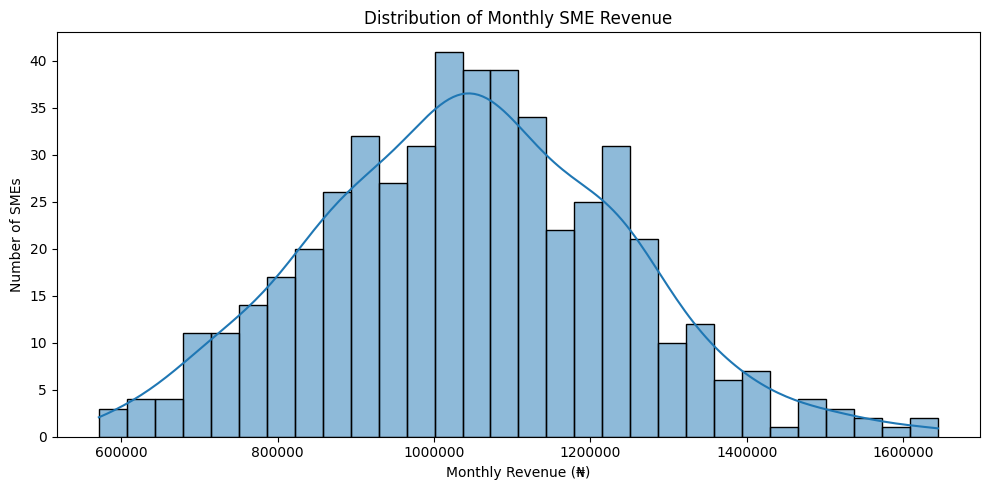

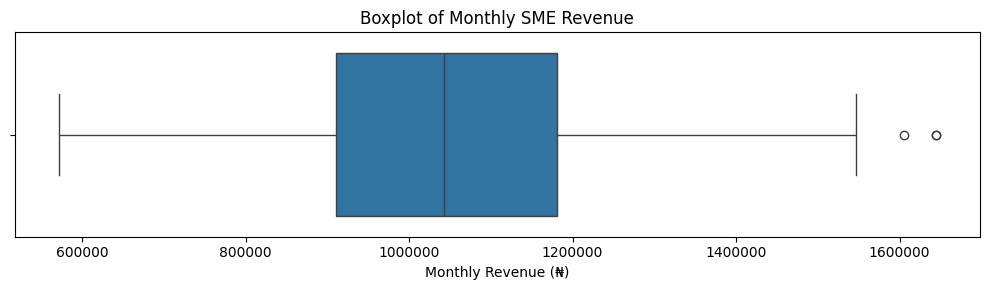

In [19]:
# ==========================================
# EXPLORATORY DATA ANALYSIS
# DISTRIBUTION OF MONTHLY REVENUE
# ==========================================

plt.figure(figsize=(10, 5))

sns.histplot(
    df["Monthly_Revenue"],
    bins=30,
    kde=True
)

plt.title("Distribution of Monthly SME Revenue")
plt.xlabel("Monthly Revenue (₦)")
plt.ylabel("Number of SMEs")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

# Boxplot to inspect potential outliers
plt.figure(figsize=(10, 3))

sns.boxplot(x=df["Monthly_Revenue"])

plt.title("Boxplot of Monthly SME Revenue")
plt.xlabel("Monthly Revenue (₦)")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

CORRELATION WITH MONTHLY REVENUE


,Correlation
Employees,0.58
Monthly_Operating_Cost,0.47
Monthly_Sales_Volume,0.36
Marketing_Expenditure,0.33
Business_Age,0.28
Customer_Retention_Rate,0.11
Digital_Adoption,0.09
Business_Training,0.05


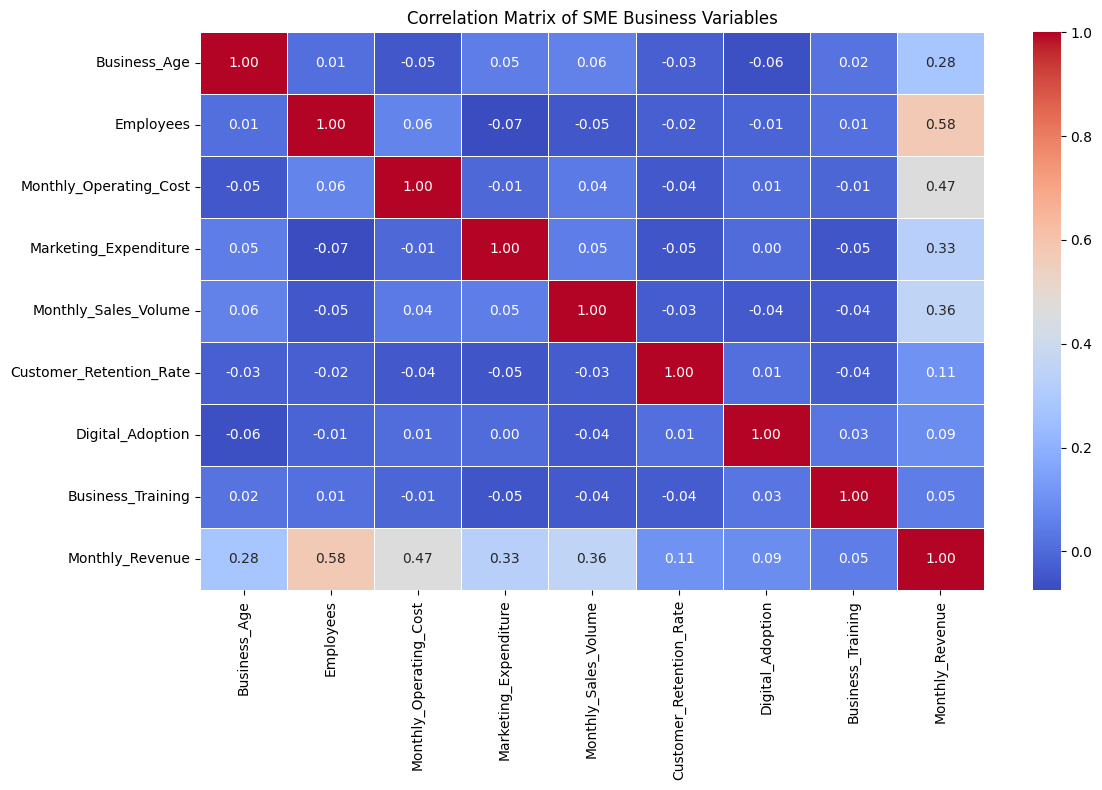

In [20]:
# ==========================================
# CORRELATION ANALYSIS
# ==========================================

correlation_matrix = df.corr(numeric_only=True)

print("CORRELATION WITH MONTHLY REVENUE")
print("=" * 45)

revenue_correlation = (
    correlation_matrix["Monthly_Revenue"]
    .drop("Monthly_Revenue")
    .sort_values(ascending=False)
)

display(revenue_correlation.to_frame("Correlation"))

# Correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of SME Business Variables")
plt.tight_layout()
plt.show()

In [21]:
# ==========================================
# FEATURE AND TARGET SEPARATION
# ==========================================

X = df.drop(columns=["Monthly_Revenue"])
y = df["Monthly_Revenue"]

print("FEATURE MATRIX")
print("Shape:", X.shape)

print("\nTARGET VARIABLE")
print("Shape:", y.shape)

print("\nFEATURE COLUMNS")
print(X.columns.tolist())

print("\nTARGET VARIABLE")
print(y.name)

FEATURE MATRIX
Shape: (500, 8)

TARGET VARIABLE
Shape: (500,)

FEATURE COLUMNS
['Business_Age', 'Employees', 'Monthly_Operating_Cost', 'Marketing_Expenditure', 'Monthly_Sales_Volume', 'Customer_Retention_Rate', 'Digital_Adoption', 'Business_Training']

TARGET VARIABLE
Monthly_Revenue


In [22]:
# ==========================================
# TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("TRAINING AND TESTING DATA")
print("=" * 40)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTRAINING OBSERVATIONS:", len(X_train))
print("TESTING OBSERVATIONS:", len(X_test))

TRAINING AND TESTING DATA
Training features: (400, 8)
Testing features: (100, 8)
Training target: (400,)
Testing target: (100,)

TRAINING OBSERVATIONS: 400
TESTING OBSERVATIONS: 100


In [23]:
# ==========================================
# MULTIPLE LINEAR REGRESSION MODEL
# ==========================================

linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

# Generate predictions
y_pred_linear = linear_model.predict(X_test)

# Evaluate model
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("MULTIPLE LINEAR REGRESSION RESULTS")
print("=" * 45)

print(f"MAE:  ₦{mae_linear:,.2f}")
print(f"RMSE: ₦{rmse_linear:,.2f}")
print(f"R-squared: {r2_linear:.4f}")

MULTIPLE LINEAR REGRESSION RESULTS
MAE:  ₦50,024.36
RMSE: ₦66,302.14
R-squared: 0.8831


In [24]:
# ==========================================
# RANDOM FOREST REGRESSION MODEL
# ==========================================

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Generate predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate model
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("RANDOM FOREST REGRESSION RESULTS")
print("=" * 45)

print(f"MAE:  ₦{mae_rf:,.2f}")
print(f"RMSE: ₦{rmse_rf:,.2f}")
print(f"R-squared: {r2_rf:.4f}")

RANDOM FOREST REGRESSION RESULTS
MAE:  ₦75,825.30
RMSE: ₦99,763.60
R-squared: 0.7354


In [25]:
# ==========================================
# MODEL PERFORMANCE COMPARISON
# ==========================================

comparison = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "Random Forest Regression"
    ],
    "MAE": [
        mae_linear,
        mae_rf
    ],
    "RMSE": [
        rmse_linear,
        rmse_rf
    ],
    "R_squared": [
        r2_linear,
        r2_rf
    ]
})

print("MODEL PERFORMANCE COMPARISON")
print("=" * 55)

display(comparison.round(4))

# Identify the model with the lowest RMSE
best_model = comparison.loc[
    comparison["RMSE"].idxmin(), "Model"
]

print("\nBEST MODEL BASED ON TEST RMSE:")
print(best_model)

MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R_squared
0,Multiple Linear Regression,"50,024.36","66,302.14",0.88
1,Random Forest Regression,"75,825.30","99,763.60",0.74



BEST MODEL BASED ON TEST RMSE:
Multiple Linear Regression


RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
1,Employees,0.35
2,Monthly_Operating_Cost,0.23
3,Marketing_Expenditure,0.17
4,Monthly_Sales_Volume,0.14
0,Business_Age,0.07
5,Customer_Retention_Rate,0.03
6,Digital_Adoption,0.01
7,Business_Training,0.01


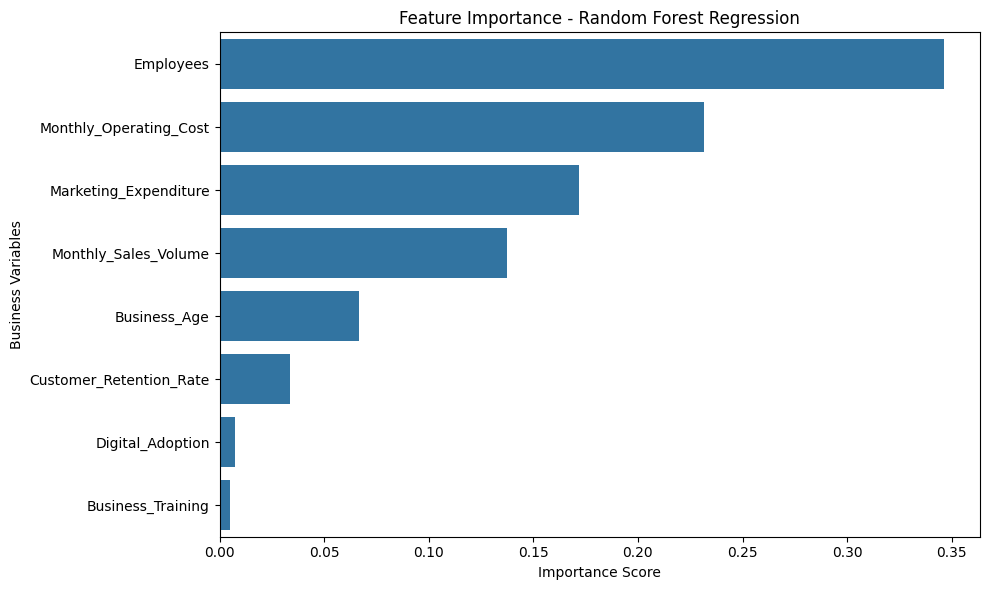

In [26]:
# ==========================================
# RANDOM FOREST FEATURE IMPORTANCE
# ==========================================

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 45)

display(feature_importance.round(4))

# Visualise feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest Regression")
plt.xlabel("Importance Score")
plt.ylabel("Business Variables")
plt.tight_layout()
plt.show()

In [27]:
# ==========================================
# 5-FOLD CROSS-VALIDATION
# ==========================================

cv_scores = cross_val_score(
    LinearRegression(),
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

cv_rmse = -cv_scores

print("LINEAR REGRESSION CROSS-VALIDATION")
print("=" * 45)

print("Fold RMSE scores:")
print(cv_rmse.round(2))

print("\nMean CV RMSE:")
print(round(cv_rmse.mean(), 2))

print("\nStandard Deviation of CV RMSE:")
print(round(cv_rmse.std(), 2))

LINEAR REGRESSION CROSS-VALIDATION
Fold RMSE scores:
[64118.69 62363.61 66015.91 67639.5  62944.67]

Mean CV RMSE:
64616.47

Standard Deviation of CV RMSE:
1960.37


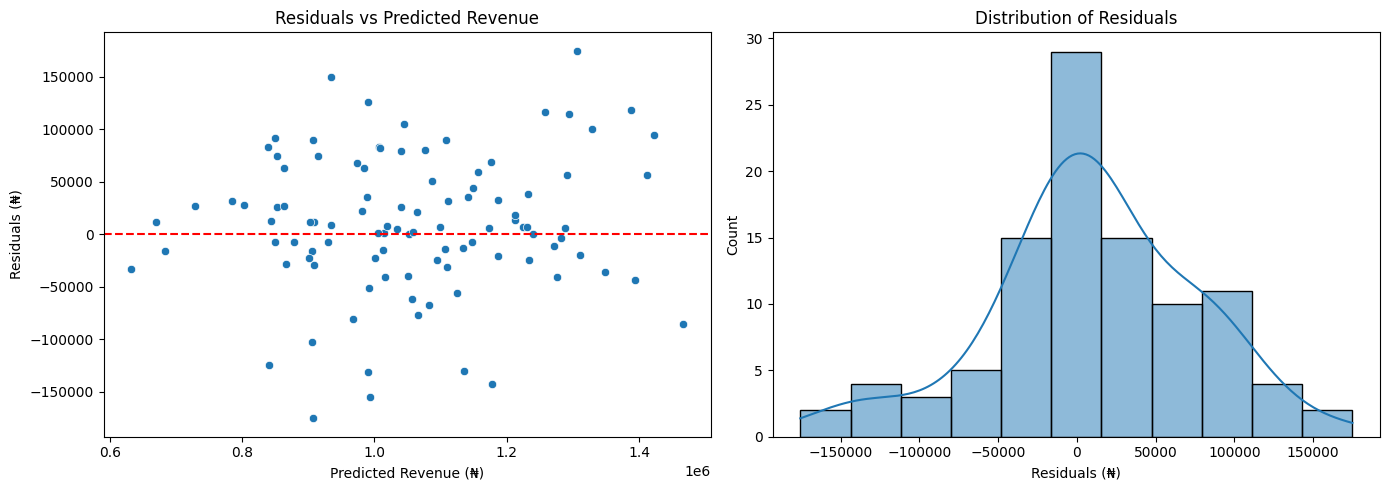

RESIDUAL SUMMARY
Mean residual: 9603.73
Residual standard deviation: 65933.4


In [28]:
# ==========================================
# RESIDUAL DIAGNOSTICS
# ==========================================

residuals = y_test - y_pred_linear

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals versus predicted values
sns.scatterplot(
    x=y_pred_linear,
    y=residuals,
    ax=axes[0]
)

axes[0].axhline(y=0, color="red", linestyle="--")
axes[0].set_title("Residuals vs Predicted Revenue")
axes[0].set_xlabel("Predicted Revenue (₦)")
axes[0].set_ylabel("Residuals (₦)")

# Distribution of residuals
sns.histplot(
    residuals,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residuals (₦)")

plt.tight_layout()
plt.show()

print("RESIDUAL SUMMARY")
print("=" * 35)
print("Mean residual:", round(residuals.mean(), 2))
print("Residual standard deviation:", round(residuals.std(), 2))

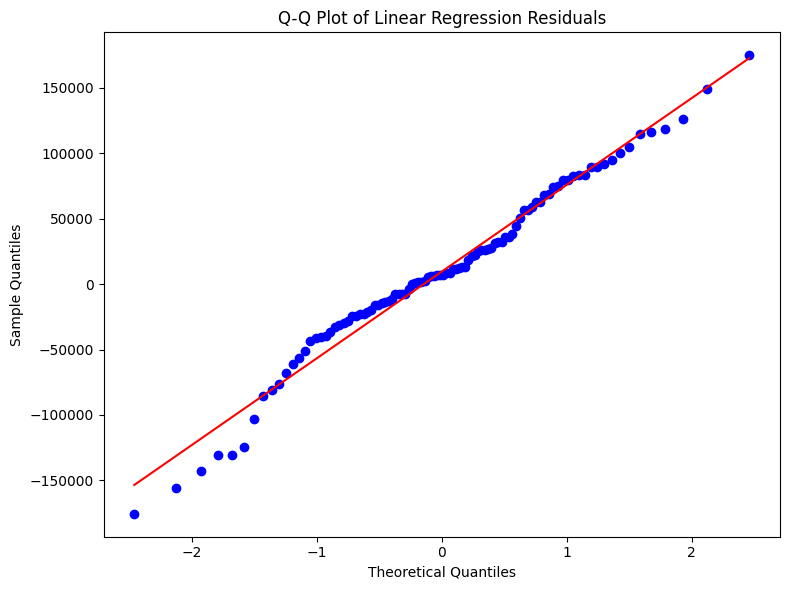

In [29]:
# ==========================================
# Q-Q PLOT FOR RESIDUAL NORMALITY
# ==========================================

import scipy.stats as stats

plt.figure(figsize=(8, 6))

stats.probplot(
    residuals,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Linear Regression Residuals")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")

plt.tight_layout()
plt.show()

In [30]:
# ==========================================
# FINAL MODEL PERFORMANCE SUMMARY
# ==========================================

final_summary = pd.DataFrame({
    "Metric": [
        "Test MAE",
        "Test RMSE",
        "Test R-squared",
        "Mean Cross-Validation RMSE",
        "CV RMSE Standard Deviation"
    ],
    "Value": [
        mae_linear,
        rmse_linear,
        r2_linear,
        cv_rmse.mean(),
        cv_rmse.std()
    ]
})

print("FINAL LINEAR REGRESSION PERFORMANCE")
print("=" * 50)

display(final_summary.round(4))

FINAL LINEAR REGRESSION PERFORMANCE


,Metric,Value
0,Test MAE,"50,024.36"
1,Test RMSE,"66,302.14"
2,Test R-squared,0.88
3,Mean Cross-Validation RMSE,"64,616.47"
4,CV RMSE Standard Deviation,"1,960.37"


## 10. Conclusion and Key Findings

This project developed and evaluated machine learning models for predicting monthly SME revenue using a synthetic dataset of 500 businesses.

Two regression algorithms were evaluated: Multiple Linear Regression and Random Forest Regression.

### Key Findings

- Multiple Linear Regression achieved a test R² of 0.8831, explaining approximately 88.31% of the variation in the held-out revenue observations.
- The model recorded a test MAE of ₦50,024.36 and RMSE of ₦66,302.14.
- Random Forest performed less effectively on this dataset, with a test R² of 0.7354 and RMSE of ₦99,763.60.
- Five-fold cross-validation produced a mean RMSE of ₦64,616.47, with a standard deviation of ₦1,960.37.
- Random Forest feature importance identified employee count, monthly operating cost, marketing expenditure, and monthly sales volume as its leading predictive features.
- Residual diagnostics indicated broadly reasonable model assumptions, although some deviation from normality was observed in the lower tail.

### Final Model Selection

Multiple Linear Regression was selected as the preferred model because it achieved lower test prediction errors and a higher R² than Random Forest Regression.

### Limitations

The dataset was synthetically generated using a predefined revenue equation with random noise. Consequently, the results demonstrate regression modelling, model comparison, validation, and diagnostic techniques rather than verified real-world SME revenue relationships.

The findings should not be interpreted as causal evidence or as proof of performance on actual business data.

### Skills Demonstrated

Python programming, exploratory data analysis, data quality assessment, correlation analysis, regression modelling, machine learning, train-test splitting, cross-validation, model evaluation, feature importance, residual diagnostics, and statistical interpretation.